# Case Study 6 — Comparative Analysis of Classification Algorithms for Bank Marketing Prediction

| | |
|---|---|
| **Subject** | Fundamentals of Data Science |
| **Course code** | 22CSC59 |
| **Faculty** | S. Durga Devi |

**Scenario.** A Portuguese bank runs telephone campaigns to sell term deposits. Calling everyone is expensive and most
customers say no. The bank wants to know, *before* calling, which customers are likely to subscribe.

**Problem statement.** Build and evaluate four classifiers — **Logistic Regression, Decision Tree, K-Nearest Neighbours and
Random Forest** — to predict whether a customer will subscribe (`y = yes`). Compare them with accuracy, precision, recall,
F1, confusion matrices and ROC-AUC, and recommend the model best suited to the bank's campaign.

**Dataset.** UCI *Bank Marketing* — `bank-additional-full.csv` (41,188 calls, May 2008 – Nov 2010, 20 inputs + target),
semicolon-delimited. This is the most complete of the four files supplied: it includes every call (not a 10% sample) and five
macro-economic indicators (employment variation rate, consumer price/confidence indices, Euribor rate, number employed).

**Important design rule.** `duration` (length of the last call) is **excluded** from all models: it is only known *after* the
call ends, so a model using it cannot be used to decide whom to call. The UCI documentation explicitly warns about this.

## 0. Setup
Import libraries and fix the random seed so every number in this notebook (and the report) is reproducible.

In [1]:
import os, warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, roc_curve, precision_recall_curve,
                             confusion_matrix, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")
os.makedirs("figures", exist_ok=True)

def savefig(name):
    plt.tight_layout()
    plt.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

## Task 1 — Data Understanding and Preprocessing
### 1.1 Load the data
**Purpose:** read the file with the correct delimiter (`;`) and inspect the first 10 records.

In [2]:
df_raw = pd.read_csv("data/bank-additional-full.csv", sep=";")
print("Dimensions (rows, columns):", df_raw.shape)
df_raw.head(10)

Dimensions (rows, columns): (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
5,45,services,married,basic.9y,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
6,59,admin.,married,professional.course,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
7,41,blue-collar,married,unknown,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
8,24,technician,single,professional.course,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
9,25,services,single,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


**Observation:** each row is one phone contact with a customer: client profile (`age` … `loan`), details of the current
campaign contact (`contact`, `month`, `day_of_week`, `duration`, `campaign`), history from earlier campaigns (`pdays`,
`previous`, `poutcome`), economic context at the time of the call, and the outcome `y`.

### 1.2 Data types and descriptive statistics
**Purpose:** confirm each column's type and the range / spread of the numeric attributes.

In [3]:
pd.DataFrame({"dtype": df_raw.dtypes.astype(str), "unique values": df_raw.nunique(),
              "example": df_raw.iloc[0]})

,dtype,unique values,example
age,int64,78,56
job,str,12,housemaid
marital,str,4,married
education,str,8,basic.4y
default,str,3,no
housing,str,3,no
loan,str,3,no
contact,str,2,telephone
month,str,10,may
day_of_week,str,5,mon


In [4]:
df_raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.02,10.42,17.00,32.00,38.00,47.00,98.00
duration,41188.0,258.29,259.28,0.00,102.00,180.00,319.00,4918.00
campaign,41188.0,2.57,2.77,1.00,1.00,2.00,3.00,56.00
pdays,41188.0,962.48,186.91,0.00,999.00,999.00,999.00,999.00
previous,41188.0,0.17,0.49,0.00,0.00,0.00,0.00,7.00
emp.var.rate,41188.0,0.08,1.57,-3.40,-1.80,1.10,1.40,1.40
cons.price.idx,41188.0,93.58,0.58,92.20,93.08,93.75,93.99,94.77
cons.conf.idx,41188.0,-40.50,4.63,-50.80,-42.70,-41.80,-36.40,-26.90
euribor3m,41188.0,3.62,1.73,0.63,1.34,4.86,4.96,5.04
nr.employed,41188.0,5167.04,72.25,4963.60,5099.10,5191.00,5228.10,5228.10


In [5]:
df_raw.describe(include=["object", "str"]).T

,count,unique,top,freq
job,41188,12,admin.,10422
marital,41188,4,married,24928
education,41188,8,university.degree,12168
default,41188,3,no,32588
housing,41188,3,yes,21576
loan,41188,3,no,33950
contact,41188,2,cellular,26144
month,41188,10,may,13769
day_of_week,41188,5,thu,8623
poutcome,41188,3,nonexistent,35563


### 1.3 Numerical, categorical and target attributes
**Purpose:** classify the attributes so each type gets the right preprocessing.

In [6]:
TARGET = "y"
numerical = df_raw.select_dtypes(include="number").columns.tolist()
categorical = [c for c in df_raw.columns if c not in numerical and c != TARGET]
print(f"Numerical ({len(numerical)}):", numerical)
print(f"Categorical ({len(categorical)}):", categorical)
print("Target:", TARGET, "->", df_raw[TARGET].unique().tolist())

Numerical (10): ['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
Categorical (10): ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
Target: y -> ['no', 'yes']


**Observation:** 10 numerical attributes (age, call statistics, campaign history, 5 economic indicators) and 10 categorical
attributes (job, marital status, education, credit default, housing/personal loan, contact type, month, weekday, previous
outcome). The target `y` is binary: `yes` / `no`.

### 1.4 Missing / unknown entries, duplicates and target distribution
**Purpose:** this dataset has no blank cells, but missing information is coded as the text `"unknown"` in categorical
columns and as `999` in `pdays` ("never contacted before"). Both must be detected explicitly.

In [7]:
print("Blank (NaN) cells:", int(df_raw.isna().sum().sum()))
unknown = (df_raw[categorical] == "unknown").sum()
unknown_tbl = pd.DataFrame({"unknown count": unknown, "unknown %": (unknown / len(df_raw) * 100).round(2)})
unknown_tbl = unknown_tbl[unknown_tbl["unknown count"] > 0].sort_values("unknown count", ascending=False)
print(unknown_tbl)
print(f"\npdays == 999 (never previously contacted): {(df_raw['pdays'] == 999).sum()} "
      f"({(df_raw['pdays'] == 999).mean():.1%})")
print("Exact duplicate rows:", df_raw.duplicated().sum())

Blank (NaN) cells: 0
           unknown count  unknown %
default             8597      20.87
education           1731       4.20
housing              990       2.40
loan                 990       2.40
job                  330       0.80
marital               80       0.19

pdays == 999 (never previously contacted): 39673 (96.3%)
Exact duplicate rows: 12


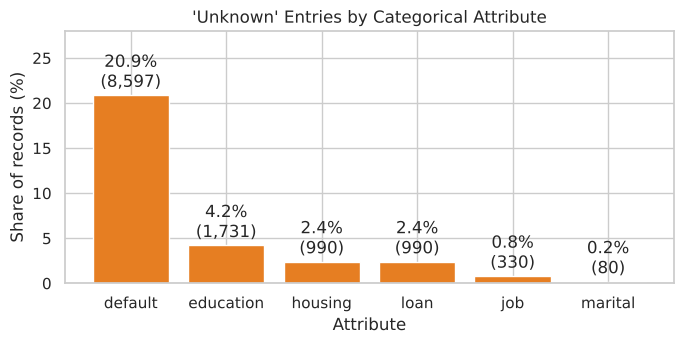

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.6))
bars = ax.bar(unknown_tbl.index, unknown_tbl["unknown %"], color="#e67e22")
ax.bar_label(bars, labels=[f"{p:.1f}%\n({c:,})" for c, p in zip(unknown_tbl['unknown count'], unknown_tbl['unknown %'])], padding=2)
ax.set_title("'Unknown' Entries by Categorical Attribute")
ax.set_xlabel("Attribute")
ax.set_ylabel("Share of records (%)")
ax.set_ylim(0, 28)
savefig("cs6_01_unknowns")

**Interpretation and handling**
- **`default` is 20.9% unknown** — far too many rows to drop. Customers who decline to state their credit-default status
  may behave differently, so `"unknown"` is **kept as its own category** in every column; the model can then learn whether
  "not disclosed" matters. Imputing the mode would erase that signal and invent information.
- `education` (4.2%), `housing`/`loan` (2.4%), `job` (0.8%) and `marital` (0.2%) have small unknown shares, handled the same way.
- **`pdays = 999` for 96.3% of customers.** Treated as a number, 999 would look like "contacted 999 days ago" — a fake extreme
  value. It is replaced by a binary flag `prev_contacted` (1 if contacted in an earlier campaign); the information about
  past campaigns is also in `previous` and `poutcome`.
- **12 exact duplicate rows** are removed so no call is counted twice (and none can appear in both training and test sets).

In [9]:
df = df_raw.drop_duplicates().reset_index(drop=True)
print("After removing duplicates:", df.shape)
counts = df[TARGET].value_counts()
pct = df[TARGET].value_counts(normalize=True) * 100
target_tbl = pd.DataFrame({"customers": counts, "percentage": pct.round(2)})
target_tbl

After removing duplicates: (41176, 21)


,customers,percentage
y,,
no,36537,88.73
yes,4639,11.27


## Task 2 — Exploratory Data Analysis
### 2.1 Target distribution
**Purpose:** count and visualise how many customers subscribed.

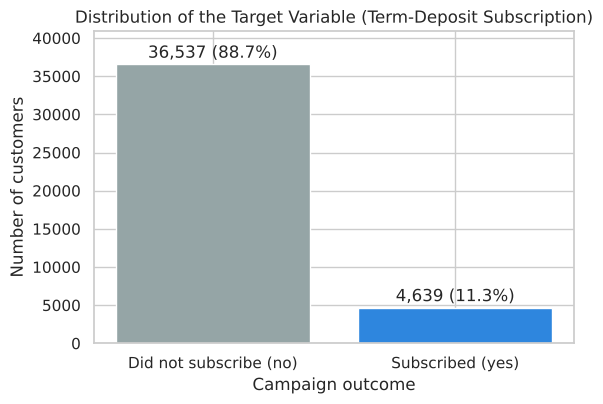

In [10]:
fig, ax = plt.subplots(figsize=(6, 4.2))
bars = ax.bar(["Did not subscribe (no)", "Subscribed (yes)"], counts[["no", "yes"]].values, color=["#95a5a6", "#2e86de"])
ax.bar_label(bars, labels=[f"{c:,} ({p:.1f}%)" for c, p in zip(counts[["no", "yes"]], pct[["no", "yes"]])], padding=2)
ax.set_title("Distribution of the Target Variable (Term-Deposit Subscription)")
ax.set_xlabel("Campaign outcome")
ax.set_ylabel("Number of customers")
ax.set_ylim(0, counts.max() * 1.12)
savefig("cs6_02_target_distribution")

**Interpretation:** only **4,639 of 41,176 customers (11.27%) subscribed**; 36,537 (88.73%) did not — about 1 success per 8
calls. This severe imbalance has a direct consequence: a "model" that always predicts *no* is **88.7% accurate** while finding
zero subscribers. Accuracy is therefore a misleading yardstick here, and recall, precision, F1 and ROC-AUC must drive the comparison.

### 2.2 Subscription rates across customer and campaign attributes
**Purpose:** find which groups subscribe more often than the 11.3% average.

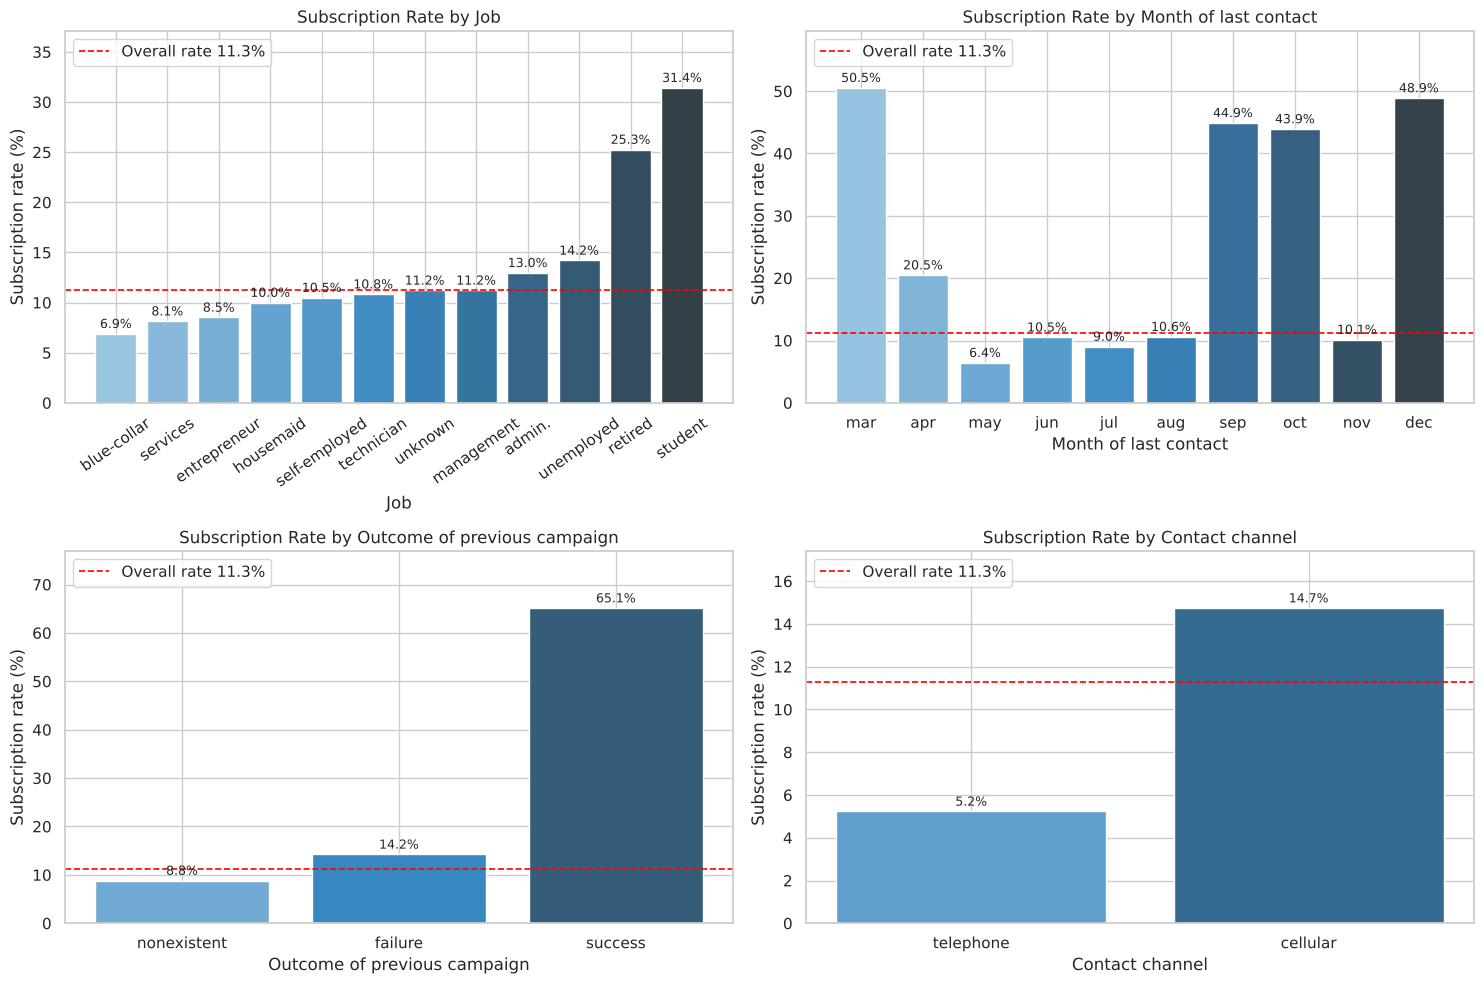

In [11]:
df["subscribed"] = (df[TARGET] == "yes").astype(int)
overall = df["subscribed"].mean() * 100
month_order = ["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
specs = [("job", None, "Job"), ("month", month_order, "Month of last contact"),
         ("poutcome", ["nonexistent", "failure", "success"], "Outcome of previous campaign"),
         ("contact", None, "Contact channel")]
for ax, (col, order, label) in zip(axes.ravel(), specs):
    g = df.groupby(col)["subscribed"].agg(["mean", "size"])
    g = g.loc[order] if order else g.sort_values("mean")
    bars = ax.bar(g.index, g["mean"] * 100, color=sns.color_palette("Blues_d", len(g)))
    ax.bar_label(bars, labels=[f"{m*100:.1f}%" for m in g["mean"]], fontsize=9, padding=2)
    ax.axhline(overall, ls="--", c="red", lw=1.2, label=f"Overall rate {overall:.1f}%")
    ax.set_title(f"Subscription Rate by {label}")
    ax.set_xlabel(label)
    ax.set_ylabel("Subscription rate (%)")
    ax.set_ylim(0, max(g["mean"] * 100) * 1.18)
    ax.tick_params(axis="x", rotation=35 if col == "job" else 0)
    ax.legend(loc="upper left")
savefig("cs6_03_rates_by_attribute")

In [12]:
for col in ["poutcome", "contact", "month", "job"]:
    t = df.groupby(col)["subscribed"].agg(rate="mean", customers="size")
    t["rate"] = (t["rate"] * 100).round(1)
    print(t.sort_values("rate", ascending=False).to_string(), "\n")

             rate  customers
poutcome                    
success      65.1       1373
failure      14.2       4252
nonexistent   8.8      35551 

           rate  customers
contact                   
cellular   14.7      26135
telephone   5.2      15041 

       rate  customers
month                 
mar    50.5        546
dec    48.9        182
sep    44.9        570
oct    43.9        717
apr    20.5       2631
aug    10.6       6176
jun    10.5       5318
nov    10.1       4100
jul     9.0       7169
may     6.4      13767 

               rate  customers
job                           
student        31.4        875
retired        25.3       1718
unemployed     14.2       1014
admin.         13.0      10419
unknown        11.2        330
management     11.2       2924
technician     10.8       6739
self-employed  10.5       1421
housemaid      10.0       1060
entrepreneur    8.5       1456
services        8.1       3967
blue-collar     6.9       9253 



**Interpretation**
- **Previous campaign outcome is the strongest behavioural signal:** customers whose previous campaign ended in *success*
  subscribe at **65.1%** — almost 6× the average — versus 14.2% after a previous *failure* and 8.8% for customers never
  contacted before.
- **Timing matters a lot:** March, September, October and December reach 44–51%, while May — the busiest month (≈13,800
  calls, a third of all contacts) — converts at only 6.4%. Months with few calls convert best, suggesting the bank called
  more selectively (or under better economic conditions) in those months.
- **Job:** students (31.4%) and retirees (25.3%) subscribe far above average; blue-collar workers (6.9%) and services staff
  (8.1%) are the least likely.
- **Channel:** mobile (`cellular`) contacts convert at 14.7% versus 5.2% for landline (`telephone`).

### 2.3 Numerical variables vs subscription outcome
**Purpose:** compare distributions of key numerical variables for subscribers and non-subscribers.

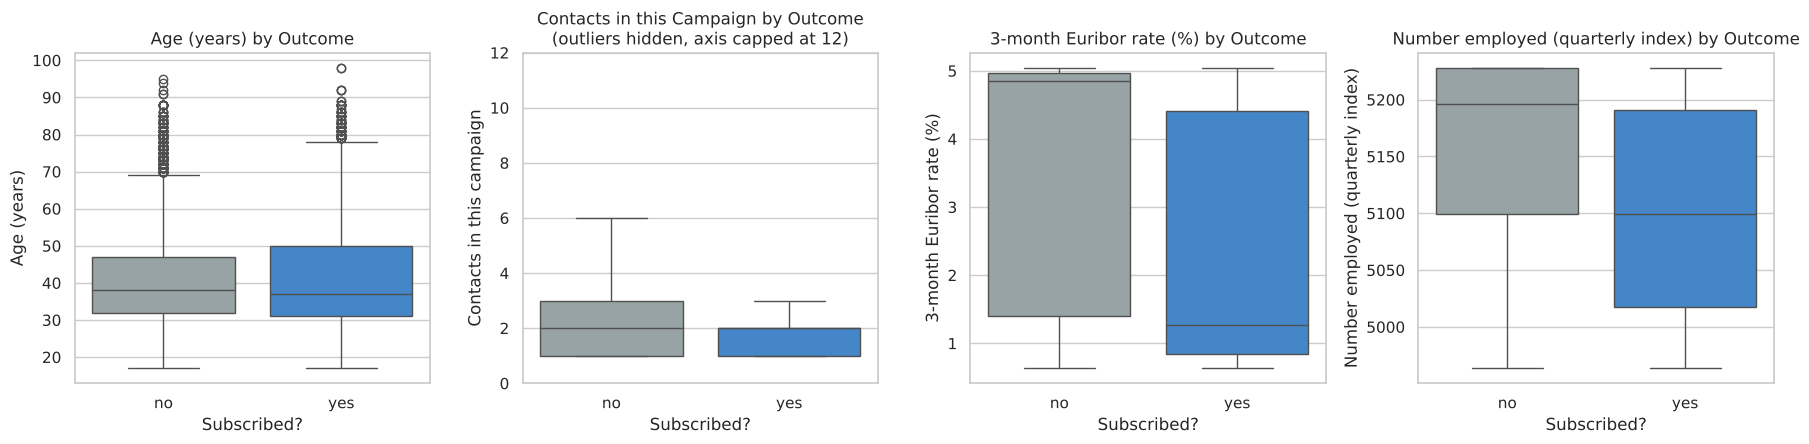

,age,campaign,previous,euribor3m,nr.employed,emp.var.rate,cons.conf.idx
y,,,,,,,
no,38.0,2.0,0.0,4.857,5195.8,1.1,-41.8
yes,37.0,2.0,0.0,1.266,5099.1,-1.8,-40.4


In [13]:
num_show = [("age", "Age (years)"), ("campaign", "Contacts in this campaign"),
            ("euribor3m", "3-month Euribor rate (%)"), ("nr.employed", "Number employed (quarterly index)")]
fig, axes = plt.subplots(1, 4, figsize=(18, 4.6))
for ax, (col, label) in zip(axes, num_show):
    sns.boxplot(data=df, x=TARGET, y=col, order=["no", "yes"], ax=ax, palette=["#95a5a6", "#2e86de"],
                showfliers=(col != "campaign"))
    ax.set_title(f"{label} by Outcome")
    ax.set_xlabel("Subscribed?")
    ax.set_ylabel(label)
axes[1].set_ylim(0, 12)
axes[1].set_title("Contacts in this Campaign by Outcome\n(outliers hidden, axis capped at 12)")
savefig("cs6_04_numeric_boxplots")
df.groupby(TARGET)[["age", "campaign", "previous", "euribor3m", "nr.employed", "emp.var.rate", "cons.conf.idx"]].median()

**Interpretation**
- **Economic context separates the classes most clearly.** Subscribers' median Euribor rate is **1.27%** versus **4.86%** for
  non-subscribers, and the median number employed is markedly lower for subscribers. When interest rates and employment fell
  (2009–2010), customers were more receptive — locking in a guaranteed deposit is more attractive in uncertain times.
- **Campaign intensity:** both groups have a median of 2 contacts, but non-subscribers have a longer tail of repeated calls —
  calling the same person many times rarely converts.
- **Age:** medians are almost identical (37 vs 38); age matters mainly at the extremes (students and retirees, seen above).

#### Subscription rate across the range of the economic indicator and call count
**Purpose:** show the *shape* of the relationship (box plots only compare centres).

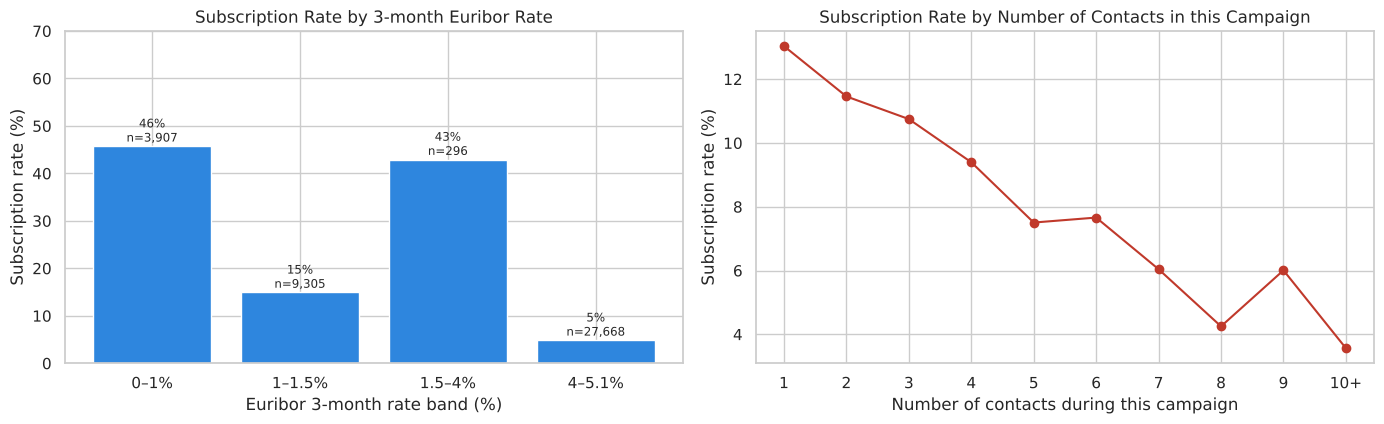

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
e = df.assign(eur_bin=pd.cut(df["euribor3m"], bins=[0, 1, 1.5, 4, 5.1]))
r = e.groupby("eur_bin", observed=True)["subscribed"].agg(["mean", "size"])
axes[0].bar(r.index.astype(str), r["mean"] * 100, color="#2e86de")
for i, (m, n) in enumerate(zip(r["mean"], r["size"])):
    axes[0].text(i, m * 100 + 1, f"{m*100:.0f}%\nn={n:,}", ha="center", fontsize=8.5)
axes[0].set_title("Subscription Rate by 3-month Euribor Rate")
axes[0].set_xlabel("Euribor 3-month rate band (%)")
axes[0].set_ylabel("Subscription rate (%)")
axes[0].set_ylim(0, 70)
axes[0].set_xticklabels(["0–1%", "1–1.5%", "1.5–4%", "4–5.1%"])

c = df.assign(c_bin=df["campaign"].clip(upper=10))
r2 = c.groupby("c_bin")["subscribed"].agg(["mean", "size"])
axes[1].plot(r2.index, r2["mean"] * 100, marker="o", color="#c0392b")
axes[1].set_xticks(range(1, 11))
axes[1].set_xticklabels([str(i) for i in range(1, 10)] + ["10+"])
axes[1].set_title("Subscription Rate by Number of Contacts in this Campaign")
axes[1].set_xlabel("Number of contacts during this campaign")
axes[1].set_ylabel("Subscription rate (%)")
savefig("cs6_05_rate_vs_numeric")

**Interpretation:** when the 3-month Euribor rate was below 1%, **45.7%** of contacted customers subscribed; at 1–1.5% the rate
was 14.9%, and above 4% — where two-thirds of all calls were made — only about **5%** subscribed. (The small 1.5–4% band, 296
calls made during the rapid 2009 rate cuts, is an exception at 42.9%.) The second chart shows diminishing returns from
repeated calls: conversion is highest on the first contact and declines with every additional call. Both are actionable:
campaign effort should respond to the rate environment, and call attempts per customer should be capped.

### 2.4 Correlation among numerical variables
**Purpose:** check linear relationships with the target and redundancy among predictors.

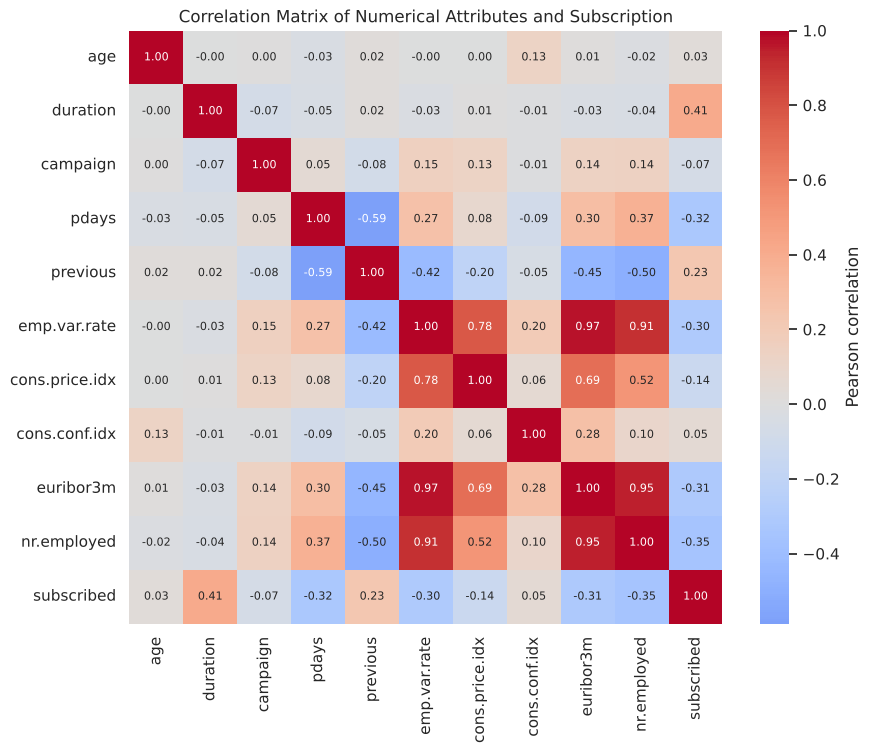

nr.employed      -0.354669
pdays            -0.324948
euribor3m        -0.307740
emp.var.rate     -0.298289
cons.price.idx   -0.136134
campaign         -0.066361
age               0.030381
cons.conf.idx     0.054802
previous          0.230202
duration          0.405297
Name: subscribed, dtype: float64

In [15]:
corr = df[numerical + ["subscribed"]].corr()
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True,
            cbar_kws={"label": "Pearson correlation"}, ax=ax, annot_kws={"size": 8})
ax.set_title("Correlation Matrix of Numerical Attributes and Subscription")
savefig("cs6_06_correlation")
corr["subscribed"].drop("subscribed").sort_values()

**Interpretation**
- `duration` has the highest correlation with subscription (+0.41) — the very reason it must be excluded: it is a
  consequence of the call outcome, not a cause known beforehand.
- Among usable predictors, `nr.employed` (−0.35), `pdays` (−0.32, i.e. *recently* contacted customers subscribe more),
  `euribor3m` (−0.31), `emp.var.rate` (−0.30) and `previous` (+0.23) are the strongest.
- **The economic indicators are highly inter-correlated** (`euribor3m`–`emp.var.rate` 0.97, `euribor3m`–`nr.employed` 0.95):
  they describe the same macro-economic cycle. This barely affects tree-based models, but it makes individual logistic
  regression coefficients unstable, and it is one reason the comparison focuses on predictive metrics rather than coefficients.

### 2.5 Statistical significance of the observed differences
**Purpose:** test whether the patterns above are larger than chance.
- Chi-square test of independence for categorical attributes (with Cramér's V as effect size: ~0.1 small, ~0.3 medium, ~0.5 large).
- Mann–Whitney U test for numerical attributes (non-normal distributions), with the rank-biserial correlation as effect size.

In [16]:
rows = []
for col in categorical:
    t = pd.crosstab(df[col], df[TARGET])
    chi2, p, dof, _ = stats.chi2_contingency(t)
    v = np.sqrt(chi2 / (t.values.sum() * (min(t.shape) - 1)))
    rows.append([col, "Chi-square", chi2, dof, p, v])
for col in [c for c in numerical if c != "duration"]:
    a, b = df.loc[df.subscribed == 1, col], df.loc[df.subscribed == 0, col]
    u, p = stats.mannwhitneyu(a, b)
    rbc = 1 - 2 * u / (len(a) * len(b))   # rank-biserial correlation
    rows.append([col, "Mann-Whitney U", u, "-", p, abs(rbc)])
tests = pd.DataFrame(rows, columns=["Attribute", "Test", "Statistic", "dof", "p-value", "Effect size"])
tests["Significant (α=0.05)"] = np.where(tests["p-value"] < 0.05, "Yes", "No")
tests["p-value"] = tests["p-value"].map(lambda p: f"{p:.2e}")
tests["Statistic"] = tests["Statistic"].round(1)
tests["Effect size"] = tests["Effect size"].round(3)
tests.sort_values("Effect size", ascending=False).reset_index(drop=True)

,Attribute,Test,Statistic,dof,p-value,Effect size,Significant (α=0.05)
0,nr.employed,Mann-Whitney U,42551676.5,-,0.00e+00,0.498,Yes
1,euribor3m,Mann-Whitney U,43488310.0,-,0.00e+00,0.487,Yes
2,emp.var.rate,Mann-Whitney U,48017796.5,-,0.00e+00,0.433,Yes
3,poutcome,Chi-square,4230.1,2,0.00e+00,0.321,Yes
4,month,Chi-square,3103.0,9,0.00e+00,0.275,Yes
5,cons.price.idx,Mann-Whitney U,66018250.5,-,1.44e-135,0.221,Yes
6,previous,Mann-Whitney U,103274848.5,-,0.00e+00,0.219,Yes
7,pdays,Mann-Whitney U,68346066.0,-,0.00e+00,0.194,Yes
8,job,Chi-square,961.7,11,3.27e-199,0.153,Yes
9,contact,Chi-square,862.1,1,1.72e-189,0.145,Yes


**Interpretation:** with 41,176 records almost every attribute is "significant" (p < 0.05) — large samples detect even tiny
differences — so the **effect size** is the informative column. The largest effects are the economic indicators
(`nr.employed`, `euribor3m`, `emp.var.rate`) and `poutcome`/`month`/`pdays`, matching the visual analysis. `housing` and
`loan` are **not significant** (p > 0.05): having a housing or personal loan does not change the subscription rate, so these
attributes are unlikely to help the models.

### 2.6 Three key observations from the EDA
1. **Subscription is rare and concentrated.** Only 11.3% subscribe, but rates reach 65% for customers whose previous campaign
   succeeded, ~31% for students and ~25% for retirees — a small, identifiable segment holds a disproportionate share of
   likely subscribers.
2. **The economic environment dominates.** When the 3-month Euribor rate was below 1%, 45.7% of contacted customers
   subscribed; above 4% (two-thirds of all calls), about 1 in 20 did. Macro indicators have the largest effect sizes of all attributes.
3. **More calls ≠ more sales.** Conversion is highest on the first contact and falls with each repeat; mobile contacts convert
   almost 3× better than landline ones.

### 1.5 Feature preparation, encoding, scaling and the 80:20 split (Task 1 continued)
**Purpose:** build the model inputs.
- Drop `duration` (not known before the call) and the helper column `subscribed`.
- Replace `pdays` by `prev_contacted` (see 1.4).
- Target: `yes` → 1, `no` → 0.
- **One-hot encode** all 10 categorical attributes (`unknown` stays a category; `handle_unknown="ignore"` protects against
  unseen levels at prediction time).
- **Standardise** numerical attributes (mean 0, SD 1). This is essential for KNN (distance-based — otherwise `nr.employed`,
  in the thousands, would swamp `age`) and for logistic regression's solver; trees are unaffected but use the same
  pipeline so all four models see identical inputs.
- **80:20 stratified split** (`random_state = 42`) — the *same* split is used for all four models.

All transformations are fitted inside a pipeline on the training data only, so nothing about the test set leaks into training.

In [17]:
data = df.copy()
data["prev_contacted"] = (data["pdays"] != 999).astype(int)
y = (data[TARGET] == "yes").astype(int)
X = data.drop(columns=[TARGET, "subscribed", "duration", "pdays"])

num_features = X.select_dtypes(include="number").columns.tolist()
cat_features = [c for c in X.columns if c not in num_features]
print("Numerical inputs :", num_features)
print("Categorical inputs:", cat_features)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
print(f"\nTraining set: {X_train.shape}  subscription rate {y_train.mean():.2%}")
print(f"Test set    : {X_test.shape}  subscription rate {y_test.mean():.2%}")

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features),
])
n_inputs = preprocessor.fit(X_train).transform(X_train.iloc[:5]).shape[1]
print(f"Model inputs after one-hot encoding: {n_inputs}")

Numerical inputs : ['age', 'campaign', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'prev_contacted']
Categorical inputs: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']

Training set: (32940, 19)  subscription rate 11.27%
Test set    : (8236, 19)  subscription rate 11.27%


Model inputs after one-hot encoding: 62


## Task 3 — Classification Model Development
**Purpose:** train the four required algorithms under identical conditions.

| Model | How it decides | Key hyper-parameter(s) tuned |
|---|---|---|
| Logistic Regression | weighted sum of inputs → sigmoid → probability | `C` (inverse regularisation strength) |
| Decision Tree | sequence of yes/no splits on single features | `max_depth`, `min_samples_leaf` (control over-fitting) |
| K-Nearest Neighbours | majority vote of the *k* most similar training customers | `n_neighbors` (k) |
| Random Forest | average vote of 300 decision trees, each grown on a bootstrap sample with random feature subsets | `max_depth`, `min_samples_leaf` |

**Fair tuning.** Untuned defaults would penalise some models unfairly (e.g. an unrestricted decision tree memorises the training
data). Each model therefore gets a small grid search with the **same 5-fold stratified cross-validation on the training set
only**, selecting by **ROC-AUC** — a threshold-independent metric that is not fooled by the class imbalance. The test set is
used exactly once, for the final comparison.

In [18]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
candidates = {
    "Logistic Regression": (LogisticRegression(max_iter=2000), {"clf__C": [0.01, 0.1, 1]}),
    "Decision Tree": (DecisionTreeClassifier(random_state=RANDOM_STATE),
                      {"clf__max_depth": [4, 6, 8, 10], "clf__min_samples_leaf": [20, 50, 100]}),
    "KNN": (KNeighborsClassifier(), {"clf__n_neighbors": [25, 51, 101]}),
    "Random Forest": (RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
                      {"clf__max_depth": [8, 12, None], "clf__min_samples_leaf": [5, 20]}),
}
models, tuning = {}, []
for name, (clf, grid) in candidates.items():
    t0 = time.time()
    search = GridSearchCV(Pipeline([("prep", preprocessor), ("clf", clf)]), grid, cv=cv,
                          scoring="roc_auc", n_jobs=-1)
    search.fit(X_train, y_train)
    models[name] = search.best_estimator_
    tuning.append({"Model": name,
                   "Best hyper-parameters": {k.replace("clf__", ""): v for k, v in search.best_params_.items()},
                   "CV ROC-AUC (train)": round(search.best_score_, 4),
                   "Tuning time (s)": round(time.time() - t0, 1)})
pd.DataFrame(tuning)

,Model,Best hyper-parameters,CV ROC-AUC (train),Tuning time (s)
0,Logistic Regression,{'C': 0.1},0.7900,3.9
1,Decision Tree,"{'max_depth': 8, 'min_samples_leaf': 20}",0.7854,7.4
2,KNN,{'n_neighbors': 101},0.7836,10.0
3,Random Forest,"{'max_depth': 12, 'min_samples_leaf': 5}",0.7991,79.4


**Observation:** all four models reach a cross-validated ROC-AUC of roughly 0.78–0.80 on the training folds. The selected
settings are moderate: the decision tree is limited in depth with a minimum leaf size (preventing memorisation), KNN prefers
a large neighbourhood (k = 101) because individual neighbours are noisy, and the random forest uses depth-limited trees.

### 3.2 Predictions, metrics and confusion matrix for each model
**Purpose:** predict the test set with every model, using the standard 0.5 probability threshold, and record all metrics in
one comparison table.

In [19]:
results, probs, preds = [], {}, {}
for name, model in models.items():
    p = model.predict_proba(X_test)[:, 1]
    yhat = (p >= 0.5).astype(int)
    probs[name], preds[name] = p, yhat
    tn, fp, fn, tp = confusion_matrix(y_test, yhat).ravel()
    results.append({"Model": name,
                    "Accuracy": accuracy_score(y_test, yhat),
                    "Precision": precision_score(y_test, yhat),
                    "Recall": recall_score(y_test, yhat),
                    "F1-score": f1_score(y_test, yhat),
                    "ROC-AUC": roc_auc_score(y_test, p),
                    "PR-AUC": average_precision_score(y_test, p),
                    "TP": tp, "FP": fp, "FN": fn, "TN": tn})
comparison = pd.DataFrame(results).set_index("Model")
baseline_acc = 1 - y_test.mean()
print(f"Baseline accuracy (always predict 'no'): {baseline_acc:.4f}")
print(f"Baseline PR-AUC (random ranking) = subscription rate: {y_test.mean():.4f}")
comparison.round(4)

Baseline accuracy (always predict 'no'): 0.8873
Baseline PR-AUC (random ranking) = subscription rate: 0.1127


,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC,TP,FP,FN,TN
Model,,,,,,,,,,
Logistic Regression,0.8990,0.6633,0.2101,0.3191,0.8004,0.4533,195,99,733,7209
Decision Tree,0.8970,0.5901,0.2823,0.3819,0.8051,0.4577,262,182,666,7126
KNN,0.8991,0.6678,0.2080,0.3172,0.7953,0.4497,193,96,735,7212
Random Forest,0.9001,0.6606,0.2328,0.3442,0.8114,0.4828,216,111,712,7197


## Task 4 — Model Performance Comparison and Visualisation
### 4.1 Comparison table (threshold 0.5)

In [20]:
comparison[["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]].round(4).style.highlight_max(axis=0, color="#cfe8ff")

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.899000,0.663300,0.210100,0.319100,0.800400
Decision Tree,0.897000,0.590100,0.282300,0.381900,0.805100
KNN,0.899100,0.667800,0.208000,0.317200,0.795300
Random Forest,0.900100,0.660600,0.232800,0.344200,0.811400


**Interpretation**
- **Accuracy is nearly useless for ranking here:** all four models score ≈ 0.90, only about one point above the 0.887
  "always say no" baseline.
- **Recall is low for every model at the 0.5 threshold (0.21–0.28):** with only 11% positives, few customers ever reach a
  50% predicted probability, so the models default to "no" and miss roughly three out of four subscribers.
- **Precision is ≈ 0.59–0.67:** when a model does flag a customer, roughly 6 in 10 of those calls convert — about 5–6× the
  11.3% base rate of calling at random.
- **Ranking ability (ROC-AUC):** Random Forest is highest (0.811), followed by Decision Tree (0.805), Logistic Regression
  (0.800) and KNN (0.795). Random Forest also has the highest PR-AUC (0.483 vs a 0.113 random baseline).
- **F1:** Decision Tree is best at the 0.5 threshold (0.382) because its leaf probabilities push more customers over 0.5
  (recall 0.282, the highest); Random Forest is second (0.344). This is a threshold effect, not better ranking — see 4.4–4.6.

### 4.2 Grouped bar chart of the four evaluation metrics

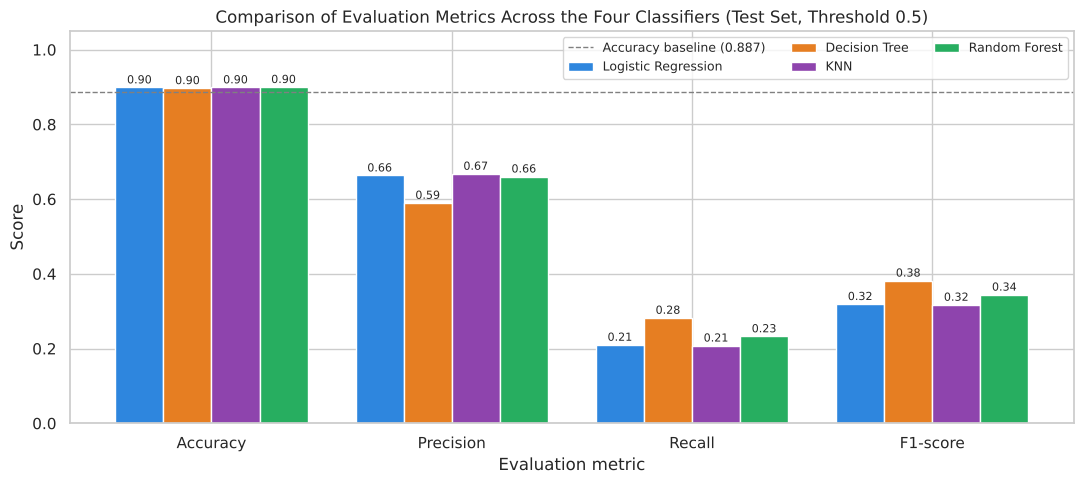

In [21]:
mcols = ["Accuracy", "Precision", "Recall", "F1-score"]
plot_df = comparison[mcols]
x = np.arange(len(mcols)); w = 0.2
fig, ax = plt.subplots(figsize=(11, 5))
colors = ["#2e86de", "#e67e22", "#8e44ad", "#27ae60"]
for i, (name, row) in enumerate(plot_df.iterrows()):
    b = ax.bar(x + (i - 1.5) * w, row.values, w, label=name, color=colors[i])
    ax.bar_label(b, fmt="%.2f", fontsize=8, padding=1)
ax.axhline(baseline_acc, ls="--", c="grey", lw=1, label=f"Accuracy baseline ({baseline_acc:.3f})")
ax.set_xticks(x); ax.set_xticklabels(mcols)
ax.set_title("Comparison of Evaluation Metrics Across the Four Classifiers (Test Set, Threshold 0.5)")
ax.set_xlabel("Evaluation metric")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)
ax.legend(ncol=3, loc="upper right", fontsize=9)
savefig("cs6_07_metric_comparison")

**Interpretation:** the accuracy bars are virtually identical and sit just above the baseline line, while recall and F1 show
the real differences — and the real weakness. The chart makes the brief's warning visible: choosing by accuracy would treat the
four models as equal and hide that each misses most subscribers at the default threshold.

### 4.3 Confusion matrix for each classifier

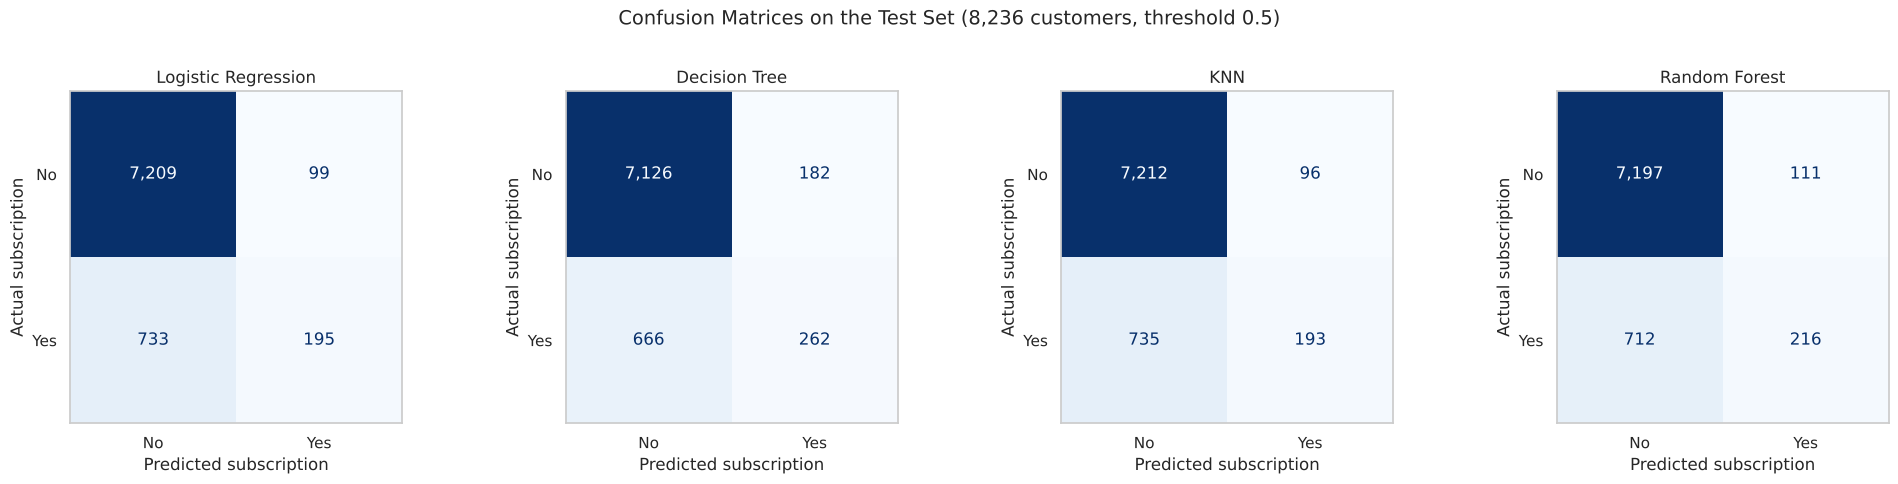

,TP,FN,FP,TN
Model,,,,
Logistic Regression,195,733,99,7209
Decision Tree,262,666,182,7126
KNN,193,735,96,7212
Random Forest,216,712,111,7197


In [22]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.6))
for ax, name in zip(axes, models):
    cm = confusion_matrix(y_test, preds[name])
    ConfusionMatrixDisplay(cm, display_labels=["No", "Yes"]).plot(ax=ax, cmap="Blues", colorbar=False, values_format=",")
    ax.grid(False)
    ax.set_title(f"{name}")
    ax.set_xlabel("Predicted subscription")
    ax.set_ylabel("Actual subscription")
fig.suptitle("Confusion Matrices on the Test Set (8,236 customers, threshold 0.5)", y=1.03, fontsize=14)
savefig("cs6_08_confusion_matrices")
comparison[["TP", "FN", "FP", "TN"]]

**Interpretation (928 actual subscribers in the test set)**
- **False negatives dominate the errors.** Every model misses 666–735 of the 928 subscribers (bottom-left cell). For the bank
  a false negative is a *lost sale*: a willing customer who is never called.
- **False positives are few** (96–182 of 7,308 non-subscribers): customers called unnecessarily. A false positive costs only one wasted call,
  so it is much cheaper than a false negative.
- Decision Tree finds the most subscribers (262) at the cost of the most false positives (182); Random Forest finds 216 with
  111 false positives; Logistic Regression and KNN are the most conservative (195 and 193 found).
- Given this cost asymmetry, the default threshold is too strict for the business — addressed in Section 4.6.

### 4.4 ROC curves and ROC-AUC
**Purpose:** compare ranking quality across all thresholds.

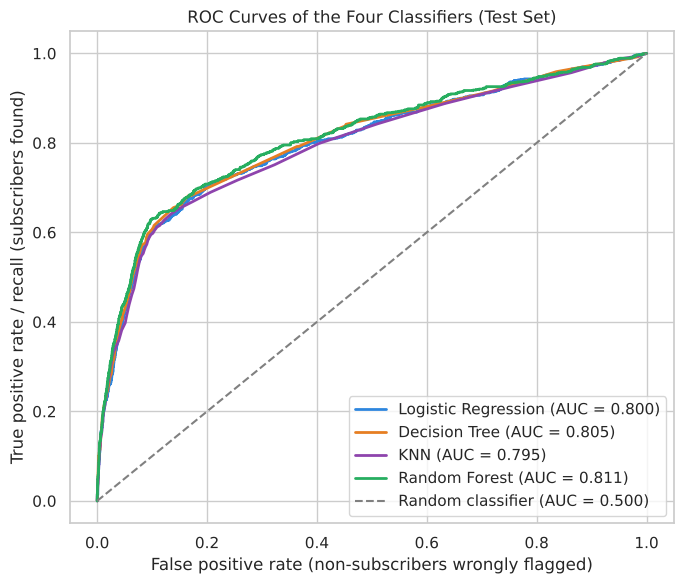

In [23]:
fig, ax = plt.subplots(figsize=(7, 6))
for (name, p), col in zip(probs.items(), colors):
    fpr, tpr, _ = roc_curve(y_test, p)
    ax.plot(fpr, tpr, lw=2, color=col, label=f"{name} (AUC = {roc_auc_score(y_test, p):.3f})")
ax.plot([0, 1], [0, 1], "--", c="grey", label="Random classifier (AUC = 0.500)")
ax.set_title("ROC Curves of the Four Classifiers (Test Set)")
ax.set_xlabel("False positive rate (non-subscribers wrongly flagged)")
ax.set_ylabel("True positive rate / recall (subscribers found)")
ax.legend(loc="lower right")
savefig("cs6_09_roc_curves")

**Interpretation:** the four curves are close together and all well above the diagonal. Random Forest's curve lies on or above
the others over most of the range (AUC 0.811). The curves rise steeply at the left: about 60–65% of subscribers can be found
while wrongly flagging only ~10% of non-subscribers. After that elbow they flatten — each additional subscriber costs many more
false positives, because the remaining subscribers look like typical non-subscribers on pre-call information alone. No model
breaks through that ceiling, which indicates the limit is in the available data, not the algorithm.

### 4.5 Precision–recall curves (imbalance-aware view)
**Purpose:** ROC curves can look optimistic when negatives vastly outnumber positives; the precision–recall curve focuses on the
rare positive class.

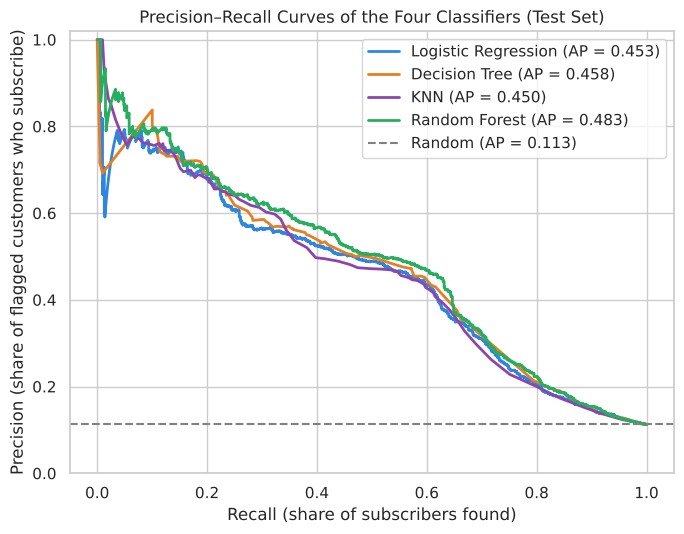

In [24]:
fig, ax = plt.subplots(figsize=(7, 5.5))
for (name, p), col in zip(probs.items(), colors):
    pr, rc, _ = precision_recall_curve(y_test, p)
    ax.plot(rc, pr, lw=2, color=col, label=f"{name} (AP = {average_precision_score(y_test, p):.3f})")
ax.axhline(y_test.mean(), ls="--", c="grey", label=f"Random (AP = {y_test.mean():.3f})")
ax.set_title("Precision–Recall Curves of the Four Classifiers (Test Set)")
ax.set_xlabel("Recall (share of subscribers found)")
ax.set_ylabel("Precision (share of flagged customers who subscribe)")
ax.set_ylim(0, 1.02)
ax.legend(loc="upper right")
savefig("cs6_10_pr_curves")

**Interpretation:** at 20% recall every model's call list is ≈ 70% precise; at 40% recall ≈ 50–55%; at 60% recall still
≈ 45% (four times the base rate); beyond ~65% recall precision drops sharply towards the 0.113 base rate — the same elbow seen
in the ROC curves. Random Forest has the highest average precision (0.483), i.e. it
keeps call lists "cleanest" across most recall levels. This confirms the ROC ranking with an imbalance-robust metric.

### 4.5b Is the difference between models statistically reliable?
**Purpose:** the ROC-AUC gaps are small (≈ 0.01), so before declaring a winner we check whether they could be chance. A paired
bootstrap resamples the 8,236 test customers 1,000 times, recomputes every model's AUC on each resample, and reports a 95%
confidence interval for the AUC difference between Random Forest and each other model. If the interval excludes 0, Random
Forest is reliably better on this data.

In [25]:
rng = np.random.default_rng(RANDOM_STATE)
yt = y_test.values
n = len(yt)
diffs = {m: [] for m in models if m != "Random Forest"}
for _ in range(1000):
    idx = rng.integers(0, n, n)
    if yt[idx].sum() == 0:
        continue
    rf_auc = roc_auc_score(yt[idx], probs["Random Forest"][idx])
    for m in diffs:
        diffs[m].append(rf_auc - roc_auc_score(yt[idx], probs[m][idx]))
boot = pd.DataFrame({m: {"Mean AUC gain of RF": np.mean(d), "95% CI low": np.percentile(d, 2.5),
                         "95% CI high": np.percentile(d, 97.5), "RF better in % of resamples": np.mean(np.array(d) > 0) * 100}
                     for m, d in diffs.items()}).T
boot.round(4)

,Mean AUC gain of RF,95% CI low,95% CI high,RF better in % of resamples
Logistic Regression,0.0109,0.0044,0.0175,100.0
Decision Tree,0.0063,-0.0003,0.0135,96.9
KNN,0.0161,0.0082,0.0248,100.0


**Interpretation**
- **vs Logistic Regression:** RF's AUC is higher by 0.011 (95% CI 0.004 to 0.018) — reliably better.
- **vs KNN:** higher by 0.016 (95% CI 0.008 to 0.025) — reliably better.
- **vs Decision Tree:** higher by 0.006 (95% CI −0.0003 to 0.0135; RF better in 96.9% of resamples) — **borderline, not
  significant at the 5% level.** The tree is a close second on ranking.
- Practical reading: Random Forest is the best ranker, but the margin is modest; tie-breakers (PR-AUC, stability) are used below.

### 4.6 Selecting the best model and a business-appropriate threshold
**Purpose:** the brief says not to choose by accuracy alone. Selection criteria, in order:
1. **ROC-AUC and PR-AUC** — ranking quality, independent of the threshold (the threshold can be moved afterwards).
2. **F1 / recall at a sensible operating point** — because a missed subscriber (false negative) costs more than an extra call.

**Random Forest** ranks first on both ROC-AUC and PR-AUC. Its threshold is then chosen **without touching the test set**: 5-fold
out-of-fold predictions on the *training* data are used to find the probability cut-off that maximises F1, and that cut-off is
then applied once to the test set.

In [26]:
best_name = comparison["ROC-AUC"].idxmax()
best = models[best_name]
oof = cross_val_predict(best, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
ths = np.round(np.arange(0.05, 0.71, 0.01), 2)
f1_oof = [f1_score(y_train, (oof >= t).astype(int)) for t in ths]
best_t = float(ths[int(np.argmax(f1_oof))])
print(f"Best model by ROC-AUC: {best_name}")
print(f"Threshold maximising F1 on training out-of-fold predictions: {best_t:.2f}")

p = probs[best_name]
yhat_t = (p >= best_t).astype(int)
tuned = pd.DataFrame({
    "Threshold 0.50": [accuracy_score(y_test, preds[best_name]), precision_score(y_test, preds[best_name]),
                       recall_score(y_test, preds[best_name]), f1_score(y_test, preds[best_name])],
    f"Threshold {best_t:.2f}": [accuracy_score(y_test, yhat_t), precision_score(y_test, yhat_t),
                                recall_score(y_test, yhat_t), f1_score(y_test, yhat_t)],
}, index=["Accuracy", "Precision", "Recall", "F1-score"]).round(4)
tuned

Best model by ROC-AUC: Random Forest
Threshold maximising F1 on training out-of-fold predictions: 0.21


,Threshold 0.50,Threshold 0.21
Accuracy,0.9001,0.8781
Precision,0.6606,0.4681
Recall,0.2328,0.6013
F1-score,0.3442,0.5264


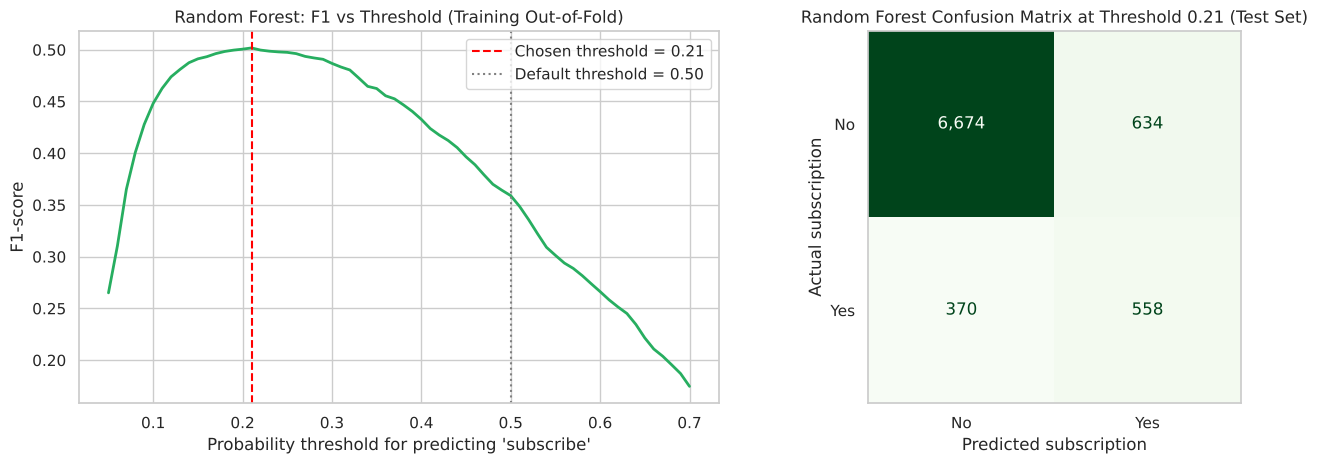

TP=558  FN=370  FP=634  TN=6674


In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].plot(ths, f1_oof, color="#27ae60", lw=2)
axes[0].axvline(best_t, ls="--", c="red", label=f"Chosen threshold = {best_t:.2f}")
axes[0].axvline(0.5, ls=":", c="grey", label="Default threshold = 0.50")
axes[0].set_title(f"{best_name}: F1 vs Threshold (Training Out-of-Fold)")
axes[0].set_xlabel("Probability threshold for predicting 'subscribe'")
axes[0].set_ylabel("F1-score")
axes[0].legend()
cm_t = confusion_matrix(y_test, yhat_t)
ConfusionMatrixDisplay(cm_t, display_labels=["No", "Yes"]).plot(ax=axes[1], cmap="Greens", colorbar=False, values_format=",")
axes[1].grid(False)
axes[1].set_title(f"{best_name} Confusion Matrix at Threshold {best_t:.2f} (Test Set)")
axes[1].set_xlabel("Predicted subscription")
axes[1].set_ylabel("Actual subscription")
savefig("cs6_11_threshold_tuning")
tn, fp, fn, tp = cm_t.ravel()
print(f"TP={tp}  FN={fn}  FP={fp}  TN={tn}")

**Interpretation**
- On the training folds, F1 peaks at a threshold of **0.21** — well below 0.5, as expected when only 11% of customers are positive.
- Applied once to the test set, the tuned Random Forest **finds 558 of the 928 subscribers (recall 0.601, up from 0.233)** while
  keeping **precision at 0.468** — almost half of all flagged customers subscribe, **4.2× the 11.3% base rate**. F1 rises from
  0.344 to **0.526**.
- It flags 1,192 of 8,236 customers (14.5%). Missed subscribers fall from 712 to 370; false positives rise from 111 to 634.
  For the bank this is the right trade: 523 extra unnecessary calls buy 342 additional term-deposit sales.
- **Accuracy falls from 0.900 to 0.878** even though the model is far more useful — a concrete demonstration of why accuracy
  must not be the selection criterion on imbalanced data.

### 4.7 Cumulative gains — how many subscribers does a targeted call list capture?
**Purpose:** translate model quality into a campaign decision: if the bank calls only the top X% of customers ranked by the model,
what share of all subscribers does it reach?

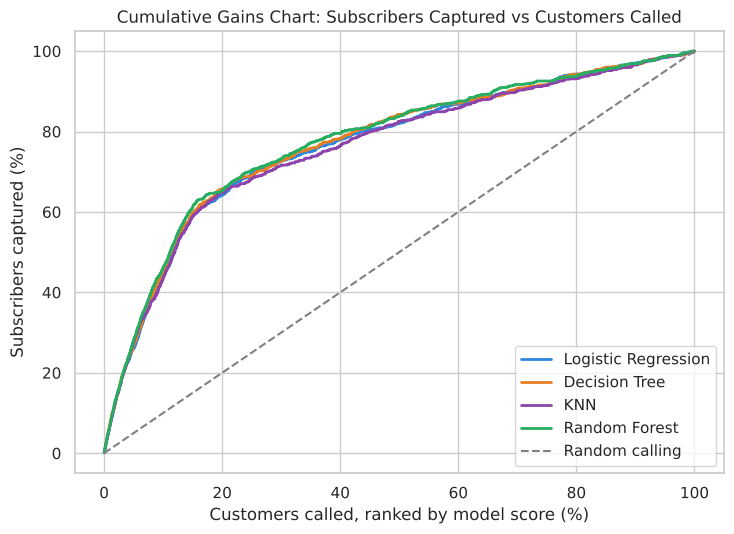

,Top 10%,Top 20%,Top 30%,Top 50%
Model,,,,
Logistic Regression,44.8,64.1,72.6,82.1
Decision Tree,45.3,65.7,72.6,84.3
KNN,43.5,64.8,71.6,82.5
Random Forest,46.2,65.3,73.3,83.8


In [28]:
fig, ax = plt.subplots(figsize=(7.5, 5.5))
gains_rows = []
for (name, pr_), col in zip(probs.items(), colors):
    order = np.argsort(-pr_)
    cum = np.cumsum(y_test.values[order]) / y_test.sum()
    frac = np.arange(1, len(cum) + 1) / len(cum)
    ax.plot(frac * 100, cum * 100, color=col, lw=2, label=name)
    gains_rows.append({"Model": name, **{f"Top {k}%": round(cum[int(len(cum) * k / 100) - 1] * 100, 1) for k in (10, 20, 30, 50)}})
ax.plot([0, 100], [0, 100], "--", c="grey", label="Random calling")
ax.set_title("Cumulative Gains Chart: Subscribers Captured vs Customers Called")
ax.set_xlabel("Customers called, ranked by model score (%)")
ax.set_ylabel("Subscribers captured (%)")
ax.legend(loc="lower right")
savefig("cs6_12_cumulative_gains")
gains = pd.DataFrame(gains_rows).set_index("Model")
gains

**Interpretation:** calling customers in the order Random Forest ranks them, the bank reaches **46.2% of all subscribers by
calling only the top 10%** of customers, **65.3% with the top 20%**, and 73.3% with the top 30% — versus 10%, 20% and 30% for
random calling (a **4.6× lift** in the top decile). All four models give similar gains curves; Random Forest leads in the
top decile, where call budgets are tightest. Beyond ~30% of the list the curves flatten: the last subscribers are expensive to reach.

### 4.8 What drives the Random Forest's predictions?
**Purpose:** check that the chosen model relies on sensible signals (impurity-based feature importance, grouped back to the
original attributes by summing their one-hot columns).

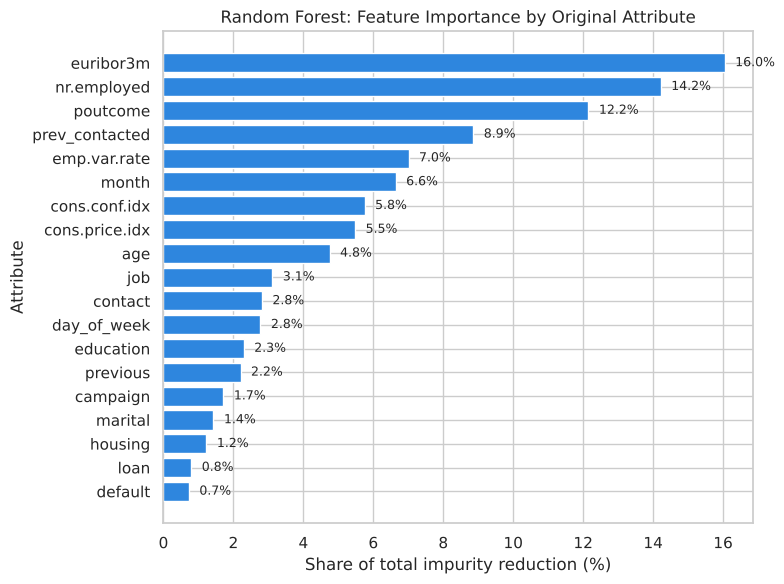

euribor3m         16.0
nr.employed       14.2
poutcome          12.2
prev_contacted     8.9
emp.var.rate       7.0
month              6.6
cons.conf.idx      5.8
cons.price.idx     5.5
age                4.8
job                3.1
contact            2.8
day_of_week        2.8
education          2.3
previous           2.2
campaign           1.7
marital            1.4
housing            1.2
loan               0.8
default            0.7
dtype: float64

In [29]:
rf = best.named_steps["clf"]
names = best.named_steps["prep"].get_feature_names_out()
imp = pd.Series(rf.feature_importances_, index=names)
orig = {}
for n, v in imp.items():
    base = n.split("__", 1)[1]
    key = next((c for c in cat_features if base.startswith(c + "_")), base)
    orig[key] = orig.get(key, 0) + v
imp_orig = pd.Series(orig).sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(imp_orig.index, imp_orig.values * 100, color="#2e86de")
for i, v in enumerate(imp_orig.values * 100):
    ax.text(v + 0.3, i, f"{v:.1f}%", va="center", fontsize=9)
ax.set_title(f"{best_name}: Feature Importance by Original Attribute")
ax.set_xlabel("Share of total impurity reduction (%)")
ax.set_ylabel("Attribute")
savefig("cs6_13_feature_importance")
(imp_orig.sort_values(ascending=False) * 100).round(1)

**Interpretation:** the Random Forest relies on the same signals the EDA identified, which supports trusting it:
- **Economic indicators** (`euribor3m` 16.0%, `nr.employed` 14.2%, `emp.var.rate` 7.0%, `cons.conf.idx` 5.8%, `cons.price.idx`
  5.5%) together account for **≈ 48%** of the model's splitting power.
- **Past-campaign history** (`poutcome` 12.2%, `prev_contacted` 8.9%, `previous` 2.2%) adds ≈ 23%.
- Timing (`month` 6.6%) and client profile (`age`, `job`, `contact`) contribute the rest.
- `housing`, `loan` and `default` are the least important (< 1.3% each) — consistent with housing and loan being statistically
  non-significant in Section 2.5.

(Impurity importance is biased towards continuous features and splits credit among correlated ones, so these shares are indicative,
not exact.)

### 4.9 Sensitivity check — why `duration` had to be excluded
**Purpose:** quantify the leakage the brief warns about by refitting logistic regression *with* `duration` on the same split.
This model is **not** a candidate — it only shows how misleading `duration` would be.

In [30]:
Xd_train = data.loc[X_train.index].drop(columns=[TARGET, "subscribed", "pdays"])
Xd_test = data.loc[X_test.index].drop(columns=[TARGET, "subscribed", "pdays"])
num_d = Xd_train.select_dtypes(include="number").columns.tolist()
leaky = Pipeline([("prep", ColumnTransformer([("num", StandardScaler(), num_d),
                                              ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features)])),
                  ("clf", LogisticRegression(max_iter=2000, C=0.1))]).fit(Xd_train, y_train)
pl = leaky.predict_proba(Xd_test)[:, 1]
print(f"Logistic Regression WITHOUT duration: ROC-AUC = {comparison.loc['Logistic Regression', 'ROC-AUC']:.4f}")
print(f"Logistic Regression WITH duration   : ROC-AUC = {roc_auc_score(y_test, pl):.4f}  (not usable before a call)")

Logistic Regression WITHOUT duration: ROC-AUC = 0.8004
Logistic Regression WITH duration   : ROC-AUC = 0.9388  (not usable before a call)


**Interpretation:** adding `duration` lifts logistic regression's ROC-AUC from **0.800 to 0.939** — an apparent jump that is
pure leakage. A long call is mostly a *consequence* of the customer being interested (a "no" ends the call quickly), and its value
is unknown until the call is over. A model reporting 0.94 would look excellent in evaluation and be useless for deciding whom to
call. Excluding it, as the brief requires, gives honest performance estimates.

## Task 5 — Interpretation and Business Recommendations
_The final narrative (best model, suitability, recommendations, limitations) is written in the cells below from the numbers
produced above._

In [31]:
summary = comparison[["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC", "PR-AUC"]].copy()
summary.loc[f"{best_name} (threshold {best_t:.2f})"] = [
    accuracy_score(y_test, yhat_t), precision_score(y_test, yhat_t), recall_score(y_test, yhat_t),
    f1_score(y_test, yhat_t), roc_auc_score(y_test, p), average_precision_score(y_test, p)]
summary.round(4)

,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
Model,,,,,,
Logistic Regression,0.8990,0.6633,0.2101,0.3191,0.8004,0.4533
Decision Tree,0.8970,0.5901,0.2823,0.3819,0.8051,0.4577
KNN,0.8991,0.6678,0.2080,0.3172,0.7953,0.4497
Random Forest,0.9001,0.6606,0.2328,0.3442,0.8114,0.4828
Random Forest (threshold 0.21),0.8781,0.4681,0.6013,0.5264,0.8114,0.4828


### 5.1 Best model
**Random Forest** (300 trees, max depth 12, min leaf 5) is the recommended model, used with a **decision threshold of 0.21**.

| Criterion | Evidence |
|---|---|
| Ranking quality | Highest ROC-AUC (0.811) and PR-AUC (0.483); reliably above Logistic Regression and KNN (bootstrap CIs exclude 0), narrowly above Decision Tree |
| Finding subscribers | At threshold 0.21: recall 0.601, precision 0.468, F1 0.526 (best F1 of any configuration) |
| Campaign efficiency | Top 10% of ranked customers contain 46.2% of all subscribers (4.6× lift) |
| Sensible drivers | Relies on economic conditions and previous-campaign outcome, matching the EDA and statistical tests |

### 5.2 Why it suits the bank's problem
- **It ranks customers well**, which is what a call centre needs: a prioritised list, not just yes/no labels. Probabilities let the
  bank set the cut-off to match each campaign's call budget.
- **It handles the data's structure:** the economic indicators are highly correlated (r up to 0.97) and their effect interacts with
  month and contact history. A forest of trees absorbs correlated inputs and non-linear interactions without manual feature
  engineering — which a single linear logistic regression cannot.
- **It is more stable than a single decision tree:** averaging 300 trees reduces the variance that makes one tree change shape with
  small data changes, at the same or better accuracy.
- **Trade-off:** it is less transparent than logistic regression and slower to train (~77 s for tuning vs ~4 s). If regulators or
  managers require coefficient-level explanations, logistic regression (AUC 0.800) is a close, fully interpretable alternative.

### 5.3 Business recommendations
1. **Score customers before every campaign and call in ranked order.** Calling the top ~15% of customers (threshold 0.21) reaches
   about 60% of all likely subscribers with roughly 47% of calls converting, instead of 11% when calling everyone. With a fixed call
   budget, the gains table tells the manager what share of subscribers each budget level reaches.
2. **Prioritise high-propensity segments and cap repeat calls.** Customers with a previous campaign success (65% conversion), students
   and retirees, and customers reachable by mobile should be contacted first; conversion falls with every repeat contact, so attempts
   per customer should be capped at about 3.
3. **Adjust campaign intensity to economic conditions** and retrain the model regularly: subscription propensity swings from ~5% to
   ~46% with the interest-rate environment, so the model (and the cut-off) must be refreshed as conditions change.

### 5.4 Limitations
1. **Time dependence of the economic features.** The data spans the 2008–2010 financial crisis, and the economic indicators are the
   same for every customer on a given day — so the model partly learns *when* calls succeed, not only *who* subscribes. Because the
   80:20 split is random, the training data includes economic periods that overlap with the test data. A time-ordered split (train
   on earlier months, test on later ones) would be a stricter test and would likely show lower performance; in a new economic regime
   the model must be revalidated before use.
2. **Class imbalance and the cost assumption.** With 11% positives, the threshold strongly changes the result. The 0.21 threshold
   maximises F1, which weights precision and recall equally; the bank's actual cost of a call versus the profit of a deposit is not
   in the data. If those costs were known, the threshold should be chosen to maximise expected profit, which could move it.
3. *(Additional)* "Unknown" values (20.9% in `default`) were kept as a category; if their meaning differs between campaigns, the
   model may learn an unstable pattern.

### 5.5 Conclusion
Four classifiers were trained on identical, leakage-free inputs and compared on a common test set. All achieved ≈ 90% accuracy — barely
above the 88.7% obtained by never predicting a subscription — showing that accuracy cannot guide model choice here. Using ROC-AUC,
PR-AUC, recall, F1 and the business cost of missed subscribers, **Random Forest with a 0.21 threshold** is the most useful model: it
identifies 60% of subscribers from 14.5% of customers, with nearly half of its calls converting.